# **Modelo de X-rays entrenado para diferenciar entre radiografías normales o con neumonía viral o bacterial**

Francisco Ferrer López

In [1]:
import os, shutil
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. **Visualización de los datos**

In [3]:
!mkdir -p /root/chest_xray_v2/
!unzip "/content/drive/MyDrive/Datos/Chest_xray_v2.zip" -d "/root/chest_xray_v2/"

Se han truncado las últimas 5000 líneas del flujo de salida.
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0433-0001.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0434-0001.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: /root/chest_xray_v2/chest_xray/train/NORMAL/IM-0440-00

Si se dejara como esta, al estar bacterial y viral dentro de pneumonia se crearian las carpetas en root como subcarpetas generando problemas, de esta manera, se hace que bacterial y viral estén al mismo nivel que normal

Después de esto se borra la carpeta de PNEUMONIA para no causar errores

In [4]:
BASE = '/root/chest_xray_v2/chest_xray'  #ruta base del dataset para no repetirla en cada línea

#creamos las carpetas BACTERIAL y VIRAL al mismo nivel que NORMAL
for split in ['train', 'test']:           #itera dos veces, una con train y otra con test
    for clase in ['BACTERIAL', 'VIRAL']:  #por cada split itera sobre las dos clases nuevas
        os.makedirs(f'{BASE}/{split}/{clase}', exist_ok=True)  #crea la carpeta, si ya existe no da error

#copiamos BACTERIAL y VIRAL fuera de PNEUMONIA a sus carpetas propias
for split in ['train', 'test']:         #mismo bucle de antes, ahora para copiar
    for tipo in ['BACTERIAL', 'VIRAL']:
        src = f'{BASE}/{split}/PNEUMONIA/{tipo}'
        dst = f'{BASE}/{split}/{tipo}'     #ruta al mismo nivel que NORMAL
        for f in os.listdir(src):      #os.listdir devuelve todos los archivos de la carpeta origen
            shutil.copy2(f'{src}/{f}', f'{dst}/{f}')   #copia cada archivo preservando sus metadatos originales

#eliminamos la carpeta PNEUMONIA para que el generador no la detecte como clase extra
for split in ['train', 'test']:      #ahora para eliminar
    pneumonia_path = f'{BASE}/{split}/PNEUMONIA'
    if os.path.exists(pneumonia_path):
        shutil.rmtree(pneumonia_path)         #elimina PNEUMONIA y todo su contenido
        print(f'Eliminada: {pneumonia_path}')    #confirma que se ha eliminado

print('Estructura 3 clases lista')
print(os.listdir(f'{BASE}/train'))

#no he conseguido quitar .DS_Store pero no molesta

Eliminada: /root/chest_xray_v2/chest_xray/train/PNEUMONIA
Eliminada: /root/chest_xray_v2/chest_xray/test/PNEUMONIA
Estructura 3 clases lista
['BACTERIAL', '.DS_Store', 'NORMAL', 'VIRAL']


Es importante ver con cuantas imágenes estamos tratando, especialmente para ver la diferente cantidad de imágenes que hay en cada clase.

Aparte, debido a que validation tiene muy pocas imágenes, he eliminado esa carpeta y las he introducido en train para hacer un split a continuación

In [29]:
print('total training NORMAL images:', len(os.listdir(f'{BASE}/train/NORMAL')))

total training NORMAL images: 1350


In [30]:
print('total training BACTERIAL images:', len(os.listdir(f'{BASE}/train/BACTERIAL')))

total training BACTERIAL images: 2531


In [31]:
print('total training VIRAL images:', len(os.listdir(f'{BASE}/train/VIRAL')))

total training VIRAL images: 1346


In [32]:
print('total test NORMAL images:', len(os.listdir(f'{BASE}/test/NORMAL')))

total test NORMAL images: 234


In [33]:
print('total test BACTERIAL images:', len(os.listdir(f'{BASE}/test/BACTERIAL')))

total test BACTERIAL images: 242


In [34]:
print('total test VIRAL images:', len(os.listdir(f'{BASE}/test/VIRAL')))

total test VIRAL images: 149


# 2. Data Augmentation y preparación de los datos

In [6]:
#preparación de las imágenes en crudo
from tensorflow.keras.preprocessing.image import ImageDataGenerator

Primero de todo, para que nuestro modelo no vea varias veces la misma imágen distorsionaremos estas cuando se las demos, ya sea cambiandoles el tamaño, la rotación, el zoom.... De esta manera no se memorizará las imágenes.

Se reservará el 20% de train para validation ya que validation no tiene suficientes imágenes

In [7]:
#usamos validation_split=0.2 para crear validación real desde train
#no hay carpeta /val separada, está integrada en train
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,              #todos estos parámetros añaden aleatoriedad: girar, desplazar...
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest',                  #rellena las esquinas al girar con el píxel más cercano
    validation_split=0.2                  #reservar 20% de /train para validación
)
test_datagen = ImageDataGenerator(rescale=1./255)

In [8]:
# usa el 80% del train
# class_mode='categorical' porque hay más de 2 clases: BACTERIAL, NORMAL, VIRAL
train_generator = train_datagen.flow_from_directory(
        f'{BASE}/train',
        target_size = (224, 224),          #resize automático para VGG16
        batch_size = 16,
        class_mode = 'categorical',        #categorical porque hay más de 2 clases
        subset = 'training',               #80% para entrenar
        shuffle = True,                    #mezcla las imágenes en cada epoch para que el modelo
                                           #no aprenda el orden de las clases sino a distinguir las radiografías
        seed = 42)

Found 4180 images belonging to 3 classes.


In [9]:
# usa el 20% del train
validation_generator = train_datagen.flow_from_directory(
    f'{BASE}/train',
    target_size = (224, 224),
    batch_size = 16,
    class_mode = 'categorical',
    subset = 'validation',                 #20% para validar
    shuffle = False,                       #shuffle=False para que las imágenes se evalúen en el mismo orden
                                           #si se mezclaran, las predicciones y las etiquetas reales no coincidirían
    seed = 42
)

print('Clases:', train_generator.class_indices)  #verifica qué número corresponde a cada clase

Found 1044 images belonging to 3 classes.
Clases: {'BACTERIAL': 0, 'NORMAL': 1, 'VIRAL': 2}


In [10]:
for data_batch, labels_batch in train_generator:
  print ('data batch shape:', data_batch.shape)
  print ('labels batch shape:', labels_batch.shape)
  break

#3 es para los colores RGB
#16 batch size
#224x224 size
#para labels ahora tenemos (16, 3) en lugar de (16,) porque cada etiqueta es un vector de 3 posiciones
#ejemplo: BACTERIAL=[1,0,0], NORMAL=[0,1,0], VIRAL=[0,0,1]

data batch shape: (16, 224, 224, 3)
labels batch shape: (16, 3)


In [11]:
#importamos el VGG16
#cargamos los pesos sacados desde imagenet, include_top falso porque nosotros le daremos la información
#VGG16 necesita un tamaño fijo para que sus capas internas funcionen correctamente
#Coincide con el target_size=(224, 224) de los generadores
from keras.applications import VGG16
conv_base = VGG16(weights = 'imagenet', include_top = False, input_shape = (224, 224, 3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [12]:
#las capas del modelo VGG16

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
#los nombres de las capas convolucionales para poder ver los nomres bien y poder copiarlos en la siguiente celda

for layer in conv_base.layers:
    if 'conv' in layer.name:
        print(layer.name)

block1_conv1
block1_conv2
block2_conv1
block2_conv2
block3_conv1
block3_conv2
block3_conv3
block4_conv1
block4_conv2
block4_conv3
block5_conv1
block5_conv2
block5_conv3


A diferencia del modelo binario, aquí se descongelan block4 y block5 en lugar de solo block5.

Distinguir bacterial de viral es más difícil visualmente, asi que intento que tenga mayor capacidad de aprendizaje

In [14]:
#descongelamos block4 y block5 para dar más capacidad al modelo
#distinguir BACTERIAL de VIRAL es más difícil que NORMAL de PNEUMONIA
#necesitamos que más capas aprendan patrones nuevos específicos de este problema
#block1, block2, block3 siguen congelados porque detectan patrones básicos
conv_base.trainable = True
for layer in conv_base.layers:
  if layer.name in ('block4_conv1', 'block4_conv2', 'block4_conv3',
                    'block5_conv1', 'block5_conv2', 'block5_conv3'):
    layer.trainable = True
  else:
    layer.trainable = False

# 3. **Modelo**

In [15]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from keras import models
from keras import layers
from tensorflow.keras.layers import Dropout

A diferencia del modelo de solo neumonia o no, este es más complejo y con 3 clases asi que deberá ser categorical.

Le he puesto más capas debido a esta complejidad

In [16]:
from keras import models
from keras import layers

model = models.Sequential()
model.add(conv_base)
model.add(layers.Flatten())
#dos capas Dense para dar más capacidad al clasificador
#distinguir 3 clases similares necesita más capacidad que el modelo binario
model.add(layers.Dense(512, activation='relu'))
model.add(Dropout(0.5))
model.add(layers.Dense(256, activation='relu'))
model.add(Dropout(0.3))
# Dense(3, softmax) porque hay 3 clases: BACTERIAL, NORMAL, VIRAL
# softmax devuelve 3 probabilidades que suman 1, la clase predicha es la de mayor probabilidad
# antes era Dense(1, sigmoid) para binario, ahora es Dense(3, softmax) para 3 clases
model.add(layers.Dense(3, activation='softmax'))

In [17]:
#los pasos por los que pasan los datos en el modelo

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    12,845,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,692,355 (105.64 MB)

 Trainable params: 25,956,867 (99.02 MB)

 Non-trainable params: 1,735,488 (6.62 MB)

In [18]:
from tensorflow.keras import optimizers

# categorical_crossentropy porque hay más de 2 clases con softmax
# learning rate más bajo que en el otro modelo porque descongelamos más capas
# con más capas entrenables hay más riesgo de destruir los pesos preentrenados de VGG16
model.compile(loss='categorical_crossentropy', optimizer=optimizers.RMSprop(learning_rate=5e-5), metrics=['acc'])

In [19]:
# class_weight para compensar el desbalance entre las 3 clases
# NORMAL: 1350, VIRAL: 1345, BACTERIAL: 2530
labels = train_generator.classes  #array con 0=BACTERIAL, 1=NORMAL, 2=VIRAL
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(labels), y=labels)
#usa una fórmula que calcula en base a cuántas imágenes hay de cada tipo para darle el peso adecuado
class_weight_dict = dict(enumerate(class_weights))  #enumerate convierte el array en {0: peso, 1: peso, 2: peso}
print('class_weights:', class_weight_dict)

class_weights: {0: np.float64(0.6884057971014492), 1: np.float64(1.2901234567901234), 2: np.float64(1.2949194547707559)}


In [20]:
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.callbacks import EarlyStopping

#guardamos el mejor modelo según val_acc
filepath = "/content/drive/MyDrive/ModelosPesos/chest_xray_v2.best.keras"
checkpoint = ModelCheckpoint(filepath, monitor='val_acc', verbose=1, save_best_only=True, mode='max')

#paramos si val_acc no mejora en 10 epochs
es = EarlyStopping(monitor='val_acc', patience=10)

callbacks_list = [checkpoint, es]

In [21]:

history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),   #calcula cuántos batches de 16 hay en total
    epochs=30,                              #30 epochs pero serán menos por el early stopping
    validation_data=validation_generator,
    validation_steps=len(validation_generator),  #cubre todas las imágenes de validación
    class_weight=class_weight_dict,
    callbacks=callbacks_list,
    verbose=1
)

Epoch 1/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - acc: 0.5543 - loss: 0.9047
Epoch 1: val_acc improved from None to 0.72605, saving model to /content/drive/MyDrive/ModelosPesos/chest_xray_v2.best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ModelosPesos/chest_xray_v2.best.keras
262/262 ━━━━━━━━━━━━━━━━━━━━ 171s 591ms/step - acc: 0.6151 - loss: 0.7775 - val_acc: 0.7261 - val_loss: 0.5940
Epoch 2/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step - acc: 0.7010 - loss: 0.6051
Epoch 2: val_acc improved from 0.72605 to 0.74425, saving model to /content/drive/MyDrive/ModelosPesos/chest_xray_v2.best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ModelosPesos/chest_xray_v2.best.keras
262/262 ━━━━━━━━━━━━━━━━━━━━ 138s 528ms/step - acc: 0.7177 - loss: 0.5832 - val_acc: 0.7443 - val_loss: 0.5470
Epoch 3/30
262/262 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step - acc: 0.7461 - loss: 0.5464
Epoch 3: val_acc did not improve from 0.74425
262/262 ━━━━━━━━━━━━━━━━━━━━ 145s 553m

In [22]:
print(history.history.keys())

dict_keys(['acc', 'loss', 'val_acc', 'val_loss'])


In [23]:
import matplotlib.pyplot as plt

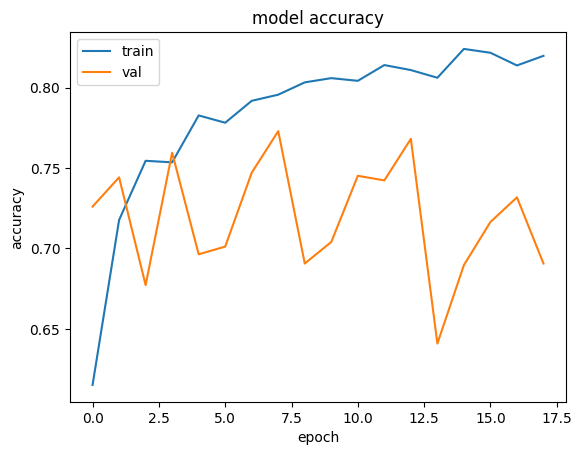

In [24]:
plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','val'], loc='upper left')
plt.show()

Train sube de manera estable pero val varía mucho, se puede apreciar overfitting en la gráfica. Para esto se usó earlystopping permitiendo quedarnos con los pesos antes de que esto ocurriera en la precisión 0.77299.

Este modelo es más complejo que el anterior que solo detectaba la diferencia entre neumonia y normal debido a la gran similitud entre viral y bacterial.

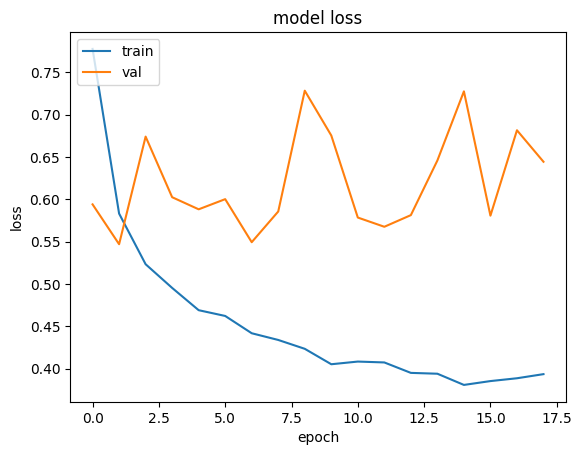

In [25]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','val'], loc='upper left')
plt.show()

Train baja de manera continua mientras que val varía mucho al igual que en accuracy mostrando overfitting. Para esto se usó early stop.

In [26]:
#cargamos el mejor modelo guardado por el ModelCheckpoint antes de evaluar en test
#sin esto evaluaríamos con el último epoch, no con el mejor
model = tf.keras.models.load_model('/content/drive/MyDrive/ModelosPesos/chest_xray_v2.best.keras')

In [27]:
#shuffle=False para evaluación correcta
test_generator = test_datagen.flow_from_directory(
    f'{BASE}/test',
    target_size = (224, 224),
    batch_size = 20,
    class_mode = 'categorical',
    shuffle = False
)

Found 624 images belonging to 3 classes.


In [28]:
scores = model.evaluate(test_generator)
print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))

32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 266ms/step - acc: 0.8494 - loss: 0.4773
compile_metrics: 84.94%


El resultado del test da mejor que el último val_acc guardado, después de un rato buscando porqué puede ocurrir esto he encontrado que se debe a las imágenes del dataset de testing.

Según el paper original (Kermany et al., 2018), el conjunto de test fue revisado por un tercer médico experto adicional para garantizar la calidad de las etiquetas, lo que lo hace más limpio y consistente que el val, extraído aleatoriamente del train.

https://www.cell.com/cell/fulltext/S0092-8674(18)30154-5

https://data.mendeley.com/datasets/rscbjbr9sj/2

De esta manera, al ser más coherentes las diferencias entre viral y bacterial que en training se consigue una precisión mayor a la del val_acc de training